# Hyperspectral Chemical Mapping: Sodium Distribution in Fish Fillets


This notebook generates pixel-level sodium (Na⁺) distribution maps from hyperspectral images (ENVI format). Pre-trained PLSR models (from Notebook 3) are applied to each pixel of the segmented sample to predict Na⁺ concentration. Two sensors are processed in parallel, **VNIR** (Specim FX10, 400-1000 nm) and **SWIR** (1000-2500 nm), using a shared pipeline.

The example dataset consists of fish-fillet samples acquired with both sensors.

**Notebook structure**

| # | Section | Purpose |
|---|---------|---------|
| 1 | Setup & Requirements | Imports and plotting style |
| 2 | Configuration | Sensor paths, crop settings, and shared parameters |
| 3 | Core Functions | Image loading, segmentation, MSC normalisation, distribution mapping |
| 4 | VNIR Chemical Mapping | Apply VNIR PLSR model to generate Na⁺ maps |
| 5 | SWIR Chemical Mapping | Apply SWIR PLSR model to generate Na⁺ maps |


## 1. Setup & Requirements

In [1]:
import os
import cv2
import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import spectral
from spectral import envi
import matplotlib.pyplot as plt
from scipy.ndimage import zoom

spectral.settings.envi_support_nonlowercase_params = True

In [2]:
custom_params = {
    "axes.spines.right": False,
    "axes.spines.top": False,
    "font.family": "arial",
    "figure.figsize": (5, 3),
    "figure.dpi": 150,
    "lines.linewidth": 1.5,
    "axes.linewidth": 1.0,
    "grid.linewidth": 0.5,
    "grid.linestyle": "--",
    "savefig.dpi": 300,
}
sns.set_theme(style="ticks", context="paper", font_scale=1.5, rc=custom_params)
plt.rcParams.update(custom_params)

## 2. Configuration

Add one entry to `SENSORS` for each camera/sensor you want to process. Per-sensor settings (paths, crop borders, model) are defined inside each entry. Settings shared by all sensors (concentration range, visualisation, segmentation) are defined separately below.

In [3]:
# ---------------------------------------------------------------------------
# Sensor configurations
# ---------------------------------------------------------------------------
# Each key defines one independent processing run.
# To process a single sensor, comment out or remove the other entry.
# Per-sensor settings (paths, cropping, model) are defined here.
# ---------------------------------------------------------------------------
SENSORS = {
    "VNIR": {
        # Data & model paths
        "data_path":          "../data/VNIR",
        "model_path":         "../output/models/vnir_plsr_model.pkl",
        "msc_reference_path": "../output/spectra/vnir_msc_reference_spectra.csv",
        "output_dir":         "../output/distribution_maps/vnir",

        # Border cropping: Specim FX10 produces highly reflective strips
        # at the image edges that interfere with Otsu thresholding.
        "crop_borders": True,
        "crop_top":    200,   # rows to remove from the top edge
        "crop_bottom": 200,   # rows to remove from the bottom edge
    },
    "SWIR": {
        "data_path":          "../data/SWIR",
        "model_path":         "../output/models/swir_plsr_model.pkl",
        "msc_reference_path": "../output/spectra/swir_msc_reference_spectra.csv",
        "output_dir":         "../output/distribution_maps/swir",
        "crop_borders": True,
        "crop_top":    0,
        "crop_bottom": 0,
    },
}

# ---------------------------------------------------------------------------
# Shared settings -- applied to all sensors
# ---------------------------------------------------------------------------
# Concentration range (ppm) -- used for clipping and colour-scale limits
PLAUSIBLE_MIN = 0
PLAUSIBLE_MAX = 2500

# Set to False to skip displaying maps in the notebook
DISPLAY_MAPS = True

SEGMENTATION_MARGIN = 5  # pixel margin around the segmented bounding box

In [4]:
for sensor, cfg in SENSORS.items():
    os.makedirs(cfg["output_dir"], exist_ok=True)
    print(f"{sensor} -> {cfg['output_dir']}")

VNIR -> ../output/distribution_maps/vnir
SWIR -> ../output/distribution_maps/swir


## 3. Core Functions

### 3.1. Image Loading & Reflectance

In [5]:
def open_hyperspectral_image(file_path):
    """Load a hyperspectral image from an ENVI header file.

    Parameters
    ----------
    file_path : str
        Path to the ENVI header file (.hdr).

    Returns
    -------
    data : numpy.ndarray or None
        3D array of shape (height, width, bands).
    wavelengths : list of float or None
        Wavelength values extracted from the header metadata.
    """
    try:
        img_data = envi.open(file_path)
        hyperspectral_data = img_data.load()
        hyperspectral_data = hyperspectral_data.transpose(1, 0, 2)
        hyperspectral_data = hyperspectral_data[:, ::-1, :]
        wavelengths = img_data.metadata.get("Wavelength", None)
        if wavelengths:
            wavelengths = [float(w) for w in wavelengths]
        return hyperspectral_data, wavelengths
    except Exception as e:
        print(f"Error loading hyperspectral image: {e}")
        return None, None


def load_and_compute_reflectance(folder_path, sample_name):
    """Load raw, white-reference and dark-reference cubes and compute reflectance.

    Reflectance = (Raw - Dark) / (White - Dark), clipped to [0, 1].

    Parameters
    ----------
    folder_path : str
        Path to the folder containing the .hdr files.
    sample_name : str
        Sample identifier used to build filenames.

    Returns
    -------
    reflectance_img : numpy.ndarray or None
        Reflectance cube clipped to [0, 1].
    wavelengths : list of float or None
        Wavelength values from the raw-image header.
    """
    file_paths = {
        "raw":   os.path.join(folder_path, f"{sample_name}.hdr"),
        "white": os.path.join(folder_path, f"WHITEREF_{sample_name}.hdr"),
        "dark":  os.path.join(folder_path, f"DARKREF_{sample_name}.hdr"),
    }

    for key, path in file_paths.items():
        if not os.path.isfile(path):
            print(f"Missing {key} reference file: {path}")
            return None, None

    raw_img,   wavelengths = open_hyperspectral_image(file_paths["raw"])
    white_img, _           = open_hyperspectral_image(file_paths["white"])
    dark_img,  _           = open_hyperspectral_image(file_paths["dark"])

    if any(img is None for img in [raw_img, white_img, dark_img]):
        print("Error loading one or more hyperspectral images")
        return None, None

    # Resize references to match the raw image (may differ in column count)
    target_cols = raw_img.shape[1]
    ref_cols    = white_img.shape[1]
    zoom_factor = (1.0, target_cols / ref_cols, 1.0)
    white_img_resized = zoom(white_img, zoom_factor, order=1)
    dark_img_resized  = zoom(dark_img,  zoom_factor, order=1)

    if raw_img.shape != white_img_resized.shape or raw_img.shape != dark_img_resized.shape:
        raise ValueError(
            f"Dimension mismatch after resizing: raw {raw_img.shape}, "
            f"white {white_img_resized.shape}, dark {dark_img_resized.shape}"
        )

    denominator = white_img_resized - dark_img_resized
    denominator[denominator == 0] = 1e-6

    reflectance_img = (raw_img - dark_img_resized) / denominator
    reflectance_img = np.clip(reflectance_img, 0, 1)

    return reflectance_img, wavelengths

### 3.2. Sample Segmentation

In [6]:
def crop_borders(cube, top=200, bottom=200):
    """Remove border rows from a hyperspectral cube.

    Some line-scan cameras (e.g. Specim FX10) produce highly reflective
    strips at the image edges that interfere with automatic thresholding.

    Parameters
    ----------
    cube : numpy.ndarray
        3D array of shape (height, width, bands).
    top : int, optional
        Pixel rows to remove from the top edge (default 200).
    bottom : int, optional
        Pixel rows to remove from the bottom edge (default 200).

    Returns
    -------
    numpy.ndarray
        Cropped cube of shape (height - top - bottom, width, bands).
    """
    h = cube.shape[0]
    if top + bottom >= h:
        raise ValueError(
            f"Crop size ({top}+{bottom}) exceeds image height ({h})"
        )
    return cube[top:h - bottom, :, :]


def find_optimal_band(reflectance_img):
    """Return the band index with the highest mean reflectance."""
    return int(np.argmax(np.mean(reflectance_img, axis=(0, 1))))


def create_sample_mask(cube_img, band_number=None):
    """Create a binary mask using Otsu thresholding on a single band.

    Parameters
    ----------
    cube_img : numpy.ndarray
        Hyperspectral image cube (height, width, bands).
    band_number : int, optional
        Band index for mask creation. If None, the band with the highest
        mean reflectance is selected automatically.

    Returns
    -------
    numpy.ndarray
        Binary mask (0 = background, 255 = sample).
    """
    if band_number is None:
        band_number = find_optimal_band(cube_img)

    band = cube_img[:, :, band_number]
    img_normalized = cv2.normalize(band, None, 0, 255, cv2.NORM_MINMAX)
    img_uint8 = img_normalized.astype(np.uint8)
    _, mask = cv2.threshold(img_uint8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return mask


def segment_sample(cube, mask, margin=None):
    """Segment the main sample region from a hyperspectral image.

    The function finds the largest closed contour in the binary mask,
    refines the mask to keep only that contour, and crops the image
    to its bounding box (with an optional margin).

    Parameters
    ----------
    cube : numpy.ndarray
        Reflectance image with values in [0, 1], shape (height, width, bands).
    mask : numpy.ndarray
        Binary mask (uint8, values 0 or 255).
    margin : int, optional
        Margin in pixels around the bounding box.
        Defaults to ``SEGMENTATION_MARGIN``.

    Returns
    -------
    segmented : numpy.ndarray
        Cropped cube containing only the sample region.
    roi_mask : numpy.ndarray
        Refined binary mask for the cropped region.
    """
    if margin is None:
        margin = SEGMENTATION_MARGIN

    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if not contours:
        print("Warning: no contours found; returning original image.")
        return cube.copy(), mask.copy()

    contours = sorted(contours, key=cv2.contourArea, reverse=True)
    roi_mask = np.zeros_like(mask, dtype=np.uint8)

    for c in contours:
        if len(cv2.approxPolyDP(c, 3, True)) >= 5:
            cv2.fillPoly(roi_mask, [c], 255)
            break
    else:
        cv2.fillPoly(roi_mask, [contours[0]], 255)

    # Element-wise multiply is correct for float arrays (avoids cv2.bitwise_and uint8 cast)
    filtered = cube * (roi_mask[:, :, np.newaxis] / 255.0)

    # Crop to bounding box
    coords = cv2.findNonZero(roi_mask)
    if coords is not None:
        x, y, w, h = cv2.boundingRect(coords)
        x = max(0, x - margin)
        y = max(0, y - margin)
        w = min(cube.shape[1] - x, w + 2 * margin)
        h = min(cube.shape[0] - y, h + 2 * margin)
        segmented = filtered[y:y + h, x:x + w]
        roi_mask  = roi_mask[y:y + h, x:x + w]
    else:
        segmented = filtered

    return segmented, roi_mask

### 3.3. Spectral Normalisation (MSC)

In [7]:
def msc_hsi(spectral_img, reference_spectra):
    """Apply Multiplicative Scatter Correction (MSC) to a hyperspectral image.

    Each pixel spectrum is corrected via linear regression against the
    reference spectrum: corrected = (spectrum - intercept) / slope.

    Parameters
    ----------
    spectral_img : numpy.ndarray
        3D array of shape (height, width, bands).
    reference_spectra : numpy.ndarray
        1D reference spectrum used for normalisation.

    Returns
    -------
    numpy.ndarray
        MSC-corrected image of the same shape as the input.
    """
    h, w, bands = spectral_img.shape
    spectra_2d    = spectral_img.reshape(-1, bands)
    normalized_2d = np.zeros_like(spectra_2d)

    for i in range(spectra_2d.shape[0]):
        fit       = np.polyfit(reference_spectra, spectra_2d[i, :], 1, full=True)
        slope     = fit[0][0]
        intercept = fit[0][1]
        if not np.isfinite(slope) or np.isclose(slope, 0):
            normalized_2d[i, :] = np.nan
        else:
            normalized_2d[i, :] = (spectra_2d[i, :] - intercept) / slope

    return normalized_2d.reshape(h, w, bands)

### 3.4. Distribution Mapping

In [8]:
def generate_distribution_map(spectral_img, mask, model_path, msc_reference_path,
                              folder_name, output_dir):
    """Generate and save a sodium distribution map for one sample.

    The pre-trained PLSR model is applied pixel-wise to predict Na+
    concentration within the segmented region.

    Parameters
    ----------
    spectral_img : numpy.ndarray
        3D hyperspectral image (height, width, bands).
    mask : numpy.ndarray
        2D binary mask (non-zero = sample pixels).
    model_path : str
        Path to the trained PLSR model (.pkl).
    msc_reference_path : str
        Path to the MSC reference spectrum CSV saved in Notebook 1.
    folder_name : str
        Sample folder name, used for the output filename.
    output_dir : str
        Directory where the map image is saved.

    Returns
    -------
    numpy.ndarray or None
        2D array of predicted Na+ concentrations (ppm).
        Background pixels are set to NaN. Returns None on failure.
    """
    model             = joblib.load(model_path)
    reference_spectra = pd.read_csv(msc_reference_path, index_col=0).squeeze().values

    # Re-apply MSC using the reference spectrum saved during Notebook 1 preprocessing,
    # ensuring consistent normalisation between training data and new images
    spectral_img = msc_hsi(spectral_img, reference_spectra)

    roi_pixels = spectral_img[mask > 0]
    if roi_pixels.shape[0] == 0:
        print("No pixels in ROI.")
        return None

    predictions         = model.predict(roi_pixels).flatten()
    clipped_predictions = np.clip(predictions, PLAUSIBLE_MIN, PLAUSIBLE_MAX)

    distribution_img = np.full(mask.shape, np.nan, dtype=np.float64)
    distribution_img[mask > 0] = clipped_predictions

    fig, ax = plt.subplots(figsize=(6, 4))
    norm = plt.Normalize(vmin=PLAUSIBLE_MIN, vmax=PLAUSIBLE_MAX)
    im   = ax.imshow(distribution_img, cmap="jet", norm=norm)

    cbar = fig.colorbar(im, ax=ax, label=r"Na$^+$ Concentration (ppm)")
    cbar.ax.yaxis.label.set_color("white")
    cbar.ax.yaxis.label.set_size(16)
    cbar.ax.tick_params(colors="white", labelsize=14)
    ax.set_facecolor("black")
    fig.patch.set_facecolor("black")
    ax.axis("off")

    os.makedirs(output_dir, exist_ok=True)
    output_path = os.path.join(output_dir, f"{folder_name}_distribution_map.png")
    plt.savefig(output_path, bbox_inches="tight", facecolor="black",
                transparent=False, dpi=300)

    if DISPLAY_MAPS:
        plt.show()
    else:
        plt.close(fig)

    return distribution_img


### 3.5. Full Processing Pipeline

In [9]:
def process_single_sample(folder_name, folder_path, cfg):
    """Run the full pipeline on one sample folder.

    Steps: load & compute reflectance -> crop borders (if enabled) ->
    create mask -> segment -> generate distribution map.

    Parameters
    ----------
    folder_name : str
        Sample folder name (e.g. 'FX10__14-C-24H').
    folder_path : str
        Full path to the 'capture/' subfolder.
    cfg : dict
        Sensor configuration entry from the SENSORS dict.

    Returns
    -------
    numpy.ndarray or None
        2D sodium distribution map, or None on failure.
    """
    print(f"Processing image: {folder_name}")

    reflectance_img, _ = load_and_compute_reflectance(folder_path, folder_name)
    if reflectance_img is None:
        print("Error: Could not load data for this sample.")
        return None

    # Apply border cropping if configured for this sensor
    if cfg.get("crop_borders", False):
        cube = crop_borders(reflectance_img,
                            top=cfg["crop_top"],
                            bottom=cfg["crop_bottom"])
    else:
        cube = reflectance_img

    # Segment sample
    mask = create_sample_mask(cube)
    cube, mask = segment_sample(cube, mask)

    # Generate distribution map
    distribution_img = generate_distribution_map(
        cube, mask,
        model_path=cfg["model_path"],
        msc_reference_path=cfg["msc_reference_path"],
        folder_name=folder_name,
        output_dir=cfg["output_dir"],
    )

    return distribution_img

## 4. VNIR Chemical Mapping

VNIR -- Number of samples to process: 6
===> Processing sample 1/6: FX10__1-C-24h
Processing image: FX10__1-C-24h


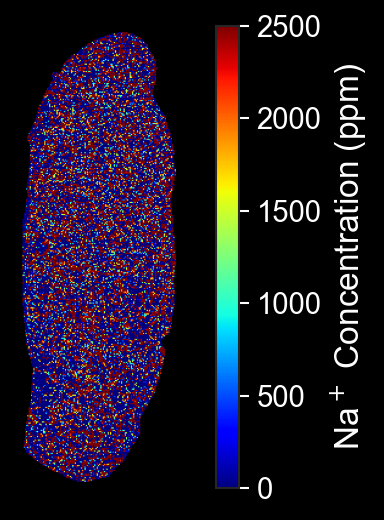

===> Processing sample 2/6: FX10__1-K-24h
Processing image: FX10__1-K-24h


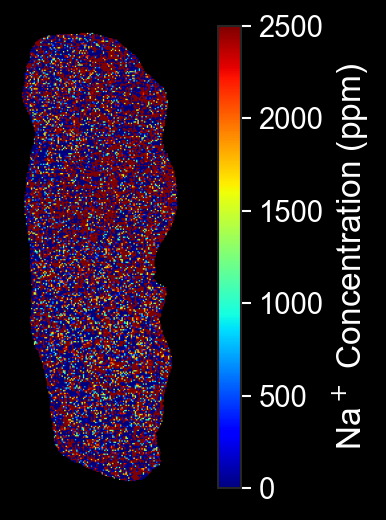

===> Processing sample 3/6: FX10__14-C-24H
Processing image: FX10__14-C-24H


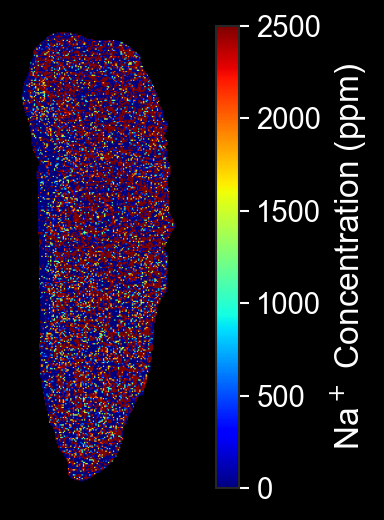

===> Processing sample 4/6: FX10__14-K-24H
Processing image: FX10__14-K-24H


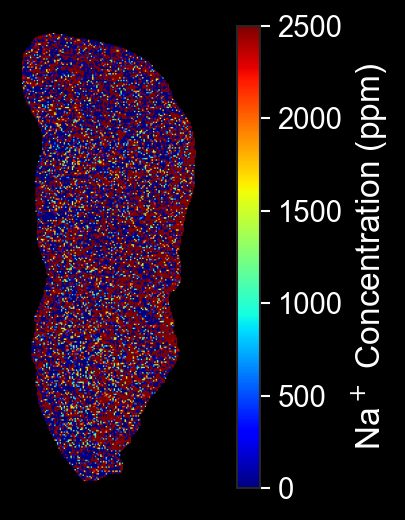

===> Processing sample 5/6: FX10__6-C-24H
Processing image: FX10__6-C-24H


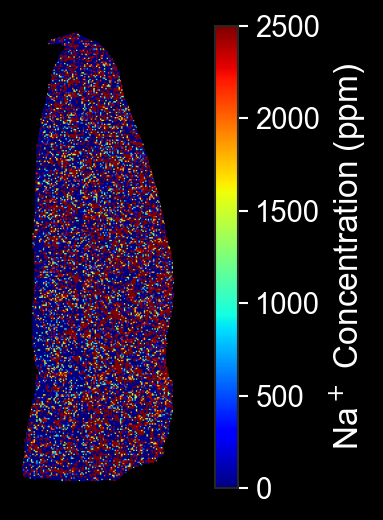

===> Processing sample 6/6: FX10__6-K-24H
Processing image: FX10__6-K-24H


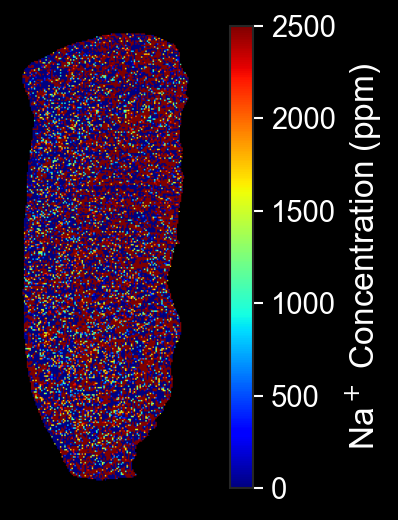

In [10]:
cfg_vnir = SENSORS["VNIR"]
sample_folders_vnir = [
    f for f in os.listdir(cfg_vnir["data_path"])
    if os.path.isdir(os.path.join(cfg_vnir["data_path"], f))
]
print(f"VNIR -- Number of samples to process: {len(sample_folders_vnir)}")

for i, folder_name in enumerate(sample_folders_vnir, start=1):
    folder_path = os.path.join(cfg_vnir["data_path"], folder_name, "capture")
    print(f"===> Processing sample {i}/{len(sample_folders_vnir)}: {folder_name}")
    process_single_sample(folder_name, folder_path, cfg_vnir)

## 5. SWIR Chemical Mapping

SWIR -- Number of samples to process: 6
===> Processing sample 1/6: SWIR__1-C-24H
Processing image: SWIR__1-C-24H


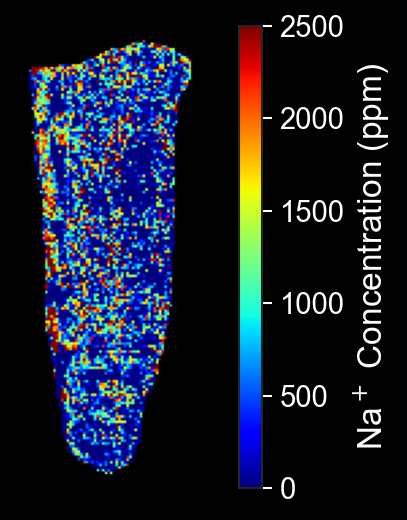

===> Processing sample 2/6: SWIR__1-K-24H
Processing image: SWIR__1-K-24H


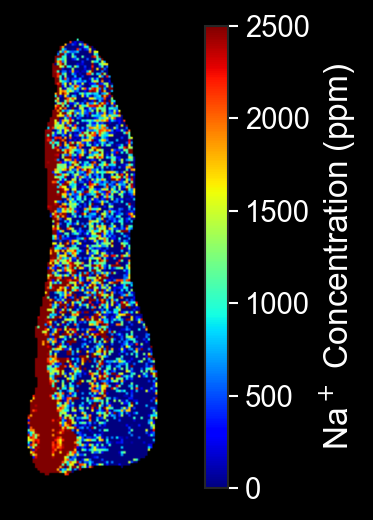

===> Processing sample 3/6: SWIR__14-C-24H
Processing image: SWIR__14-C-24H


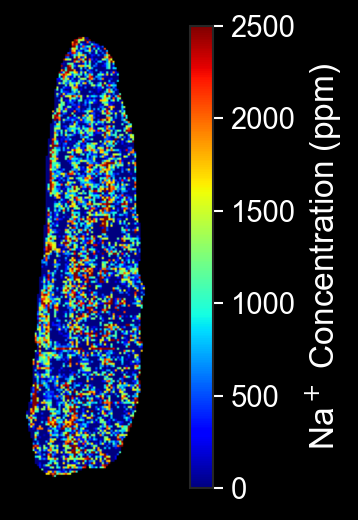

===> Processing sample 4/6: SWIR__14-K-24H
Processing image: SWIR__14-K-24H


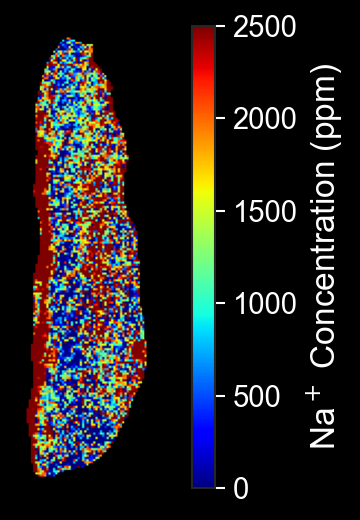

===> Processing sample 5/6: SWIR__6-C-24H
Processing image: SWIR__6-C-24H


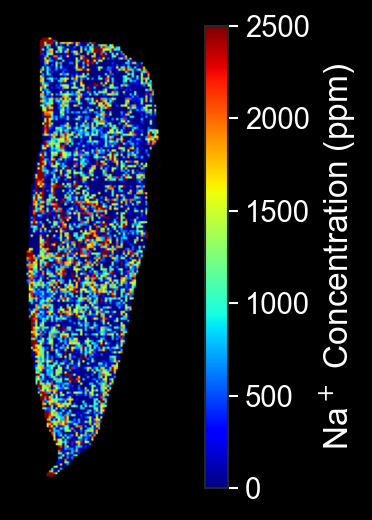

===> Processing sample 6/6: SWIR__6-K-24H
Processing image: SWIR__6-K-24H


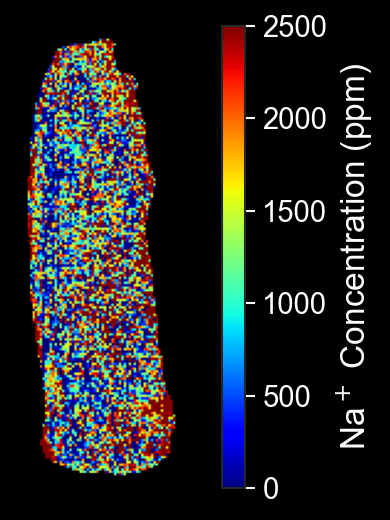

In [11]:
cfg_swir = SENSORS["SWIR"]
sample_folders_swir = [
    f for f in os.listdir(cfg_swir["data_path"])
    if os.path.isdir(os.path.join(cfg_swir["data_path"], f))
]
print(f"SWIR -- Number of samples to process: {len(sample_folders_swir)}")

for i, folder_name in enumerate(sample_folders_swir, start=1):
    folder_path = os.path.join(cfg_swir["data_path"], folder_name, "capture")
    print(f"===> Processing sample {i}/{len(sample_folders_swir)}: {folder_name}")
    process_single_sample(folder_name, folder_path, cfg_swir)

---

**Output**

Distribution maps are saved as PNG files (300 DPI, jet colormap), one file per sample:
- `output/distribution_maps/vnir/{sample_name}_distribution_map.png`
- `output/distribution_maps/swir/{sample_name}_distribution_map.png`

---

**Troubleshooting**

| Symptom | Likely cause | Solution |
|---------|-------------|---------|
| `Missing raw/white/dark reference file` | File not found at expected path | Check that `data_path` in `SENSORS` points to the correct folder and that all three `.hdr` files are present in `capture/` |
| `Dimension mismatch after resizing` | Reference cubes have incompatible shapes | Verify that raw, white and dark files belong to the same acquisition |
| `Warning: no contours found` | Otsu threshold failed (uniform image or empty ROI) | Inspect the reflectance cube; the sample may be entirely saturated or the image cropping may be too aggressive |
| Distribution map looks noisy or wrong | Wrong MSC reference or mismatched wavelength axis | Make sure `msc_reference_path` in `SENSORS` points to the reference saved in Notebook 1 and that the model was trained on the same camera/wavelength range |
| Model file not found | PLSR model not yet created | Run Notebook 3 first to train and save the model |
